# Support Vector Machines and Kernels

![SVM.png](Assets/SVM.png)

# Obiectivele cursului
- Aplicarea metodei vectorilor de suport (SVM) — un algoritm popular utilizat pentru sarcini de clasificare
- Recunoașterea similitudinii dintre SVM și regresia logistică
- Calcularea funcției de pierdere pentru SVM
- Aplicarea regularizării în SVM și studierea recomandărilor privind obținerea unei clasificări neliniare cu ajutorul SVM

## Introducere
În aceste exerciții vom folosi un set de date privind calitatea vinului. Acest set de date conține diverse proprietăți chimice ale vinului, precum aciditatea, conținutul de zahăr, pH-ul și conținutul de alcool. De asemenea, conține o măsură a calității (de la 3 la 9, unde scorul cel mai mare indică cea mai bună calitate) și culoarea (roșu sau alb). Numele fișierului: `Wine_Quality_Data.csv`.

In [1]:
from __future__ import print_function
import os
import warnings
warnings.filterwarnings('ignore')
data_path = ['data']

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.svm import LinearSVC
from sklearn.svm import SVC
from sklearn.kernel_approximation import Nystroem
from sklearn.linear_model import SGDClassifier
from sklearn.preprocessing import MinMaxScaler

# sklearnex (Intel Extension) accelereaza sklearn; daca nu este instalat continuam fara el
try:
    from sklearnex import patch_sklearn
    patch_sklearn()
except ImportError:
    print('sklearnex nu este instalat - se foloseste scikit-learn standard')

sklearnex nu este instalat - se foloseste scikit-learn standard


## Întrebarea 1
* Importul datelor.
* Creați variabila țintă `y` sub forma unei coloane cu valori 1/0, unde 1 înseamnă vin roșu.
* Creați un grafic pereche pentru setul de date.
* Creați un grafic cu bare care să ilustreze corelația dintre fiecare coloană și `y`.
* Selectați cele două câmpuri cu cea mai mare corelație (folosind valorile corelației absolute) și creați `X`.
* Folosiți MinMaxScaler pentru a scala `X`. Rețineți că rezultatul va fi un np.array. Transformați-l din nou într-un DataFrame și redenumiți coloanele în consecință.

In [2]:
# Citim datele
filepath = 'Wine_Quality_Data - Wine_Quality_Data.csv'
data = pd.read_csv(filepath)

print(data.shape)
data.head()

(6497, 13)


,fixed_acidity,volatile_acidity,citric_acid,residual_sugar,chlorides,free_sulfur_dioxide,total_sulfur_dioxide,density,pH,sulphates,alcohol,quality,color
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,red
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,red
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,red
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,red
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,red


In [3]:
# Tipurile de date si numarul de vinuri pe fiecare culoare
print(data.dtypes)
data['color'].value_counts()

fixed_acidity           float64
volatile_acidity        float64
citric_acid             float64
residual_sugar          float64
chlorides               float64
free_sulfur_dioxide     float64
total_sulfur_dioxide    float64
density                 float64
pH                      float64
sulphates               float64
alcohol                 float64
quality                   int64
color                       str
dtype: object


color
white    4898
red      1599
Name: count, dtype: int64

In [4]:
# Variabila tinta: 1 = vin rosu, 0 = vin alb
y = (data['color'] == 'red').astype(int)
fields = list(data.columns[:-1])  # toate coloanele numerice (fara 'color')

y.value_counts()

color
0    4898
1    1599
Name: count, dtype: int64

Graficul pereche (pairplot) pentru setul de date. Setul are aproape 6500 de randuri, asa ca folosim un esantion de 1000 de randuri pentru ca graficul sa se genereze rapid si sa fie lizibil. Culoarea punctelor indica tipul vinului.

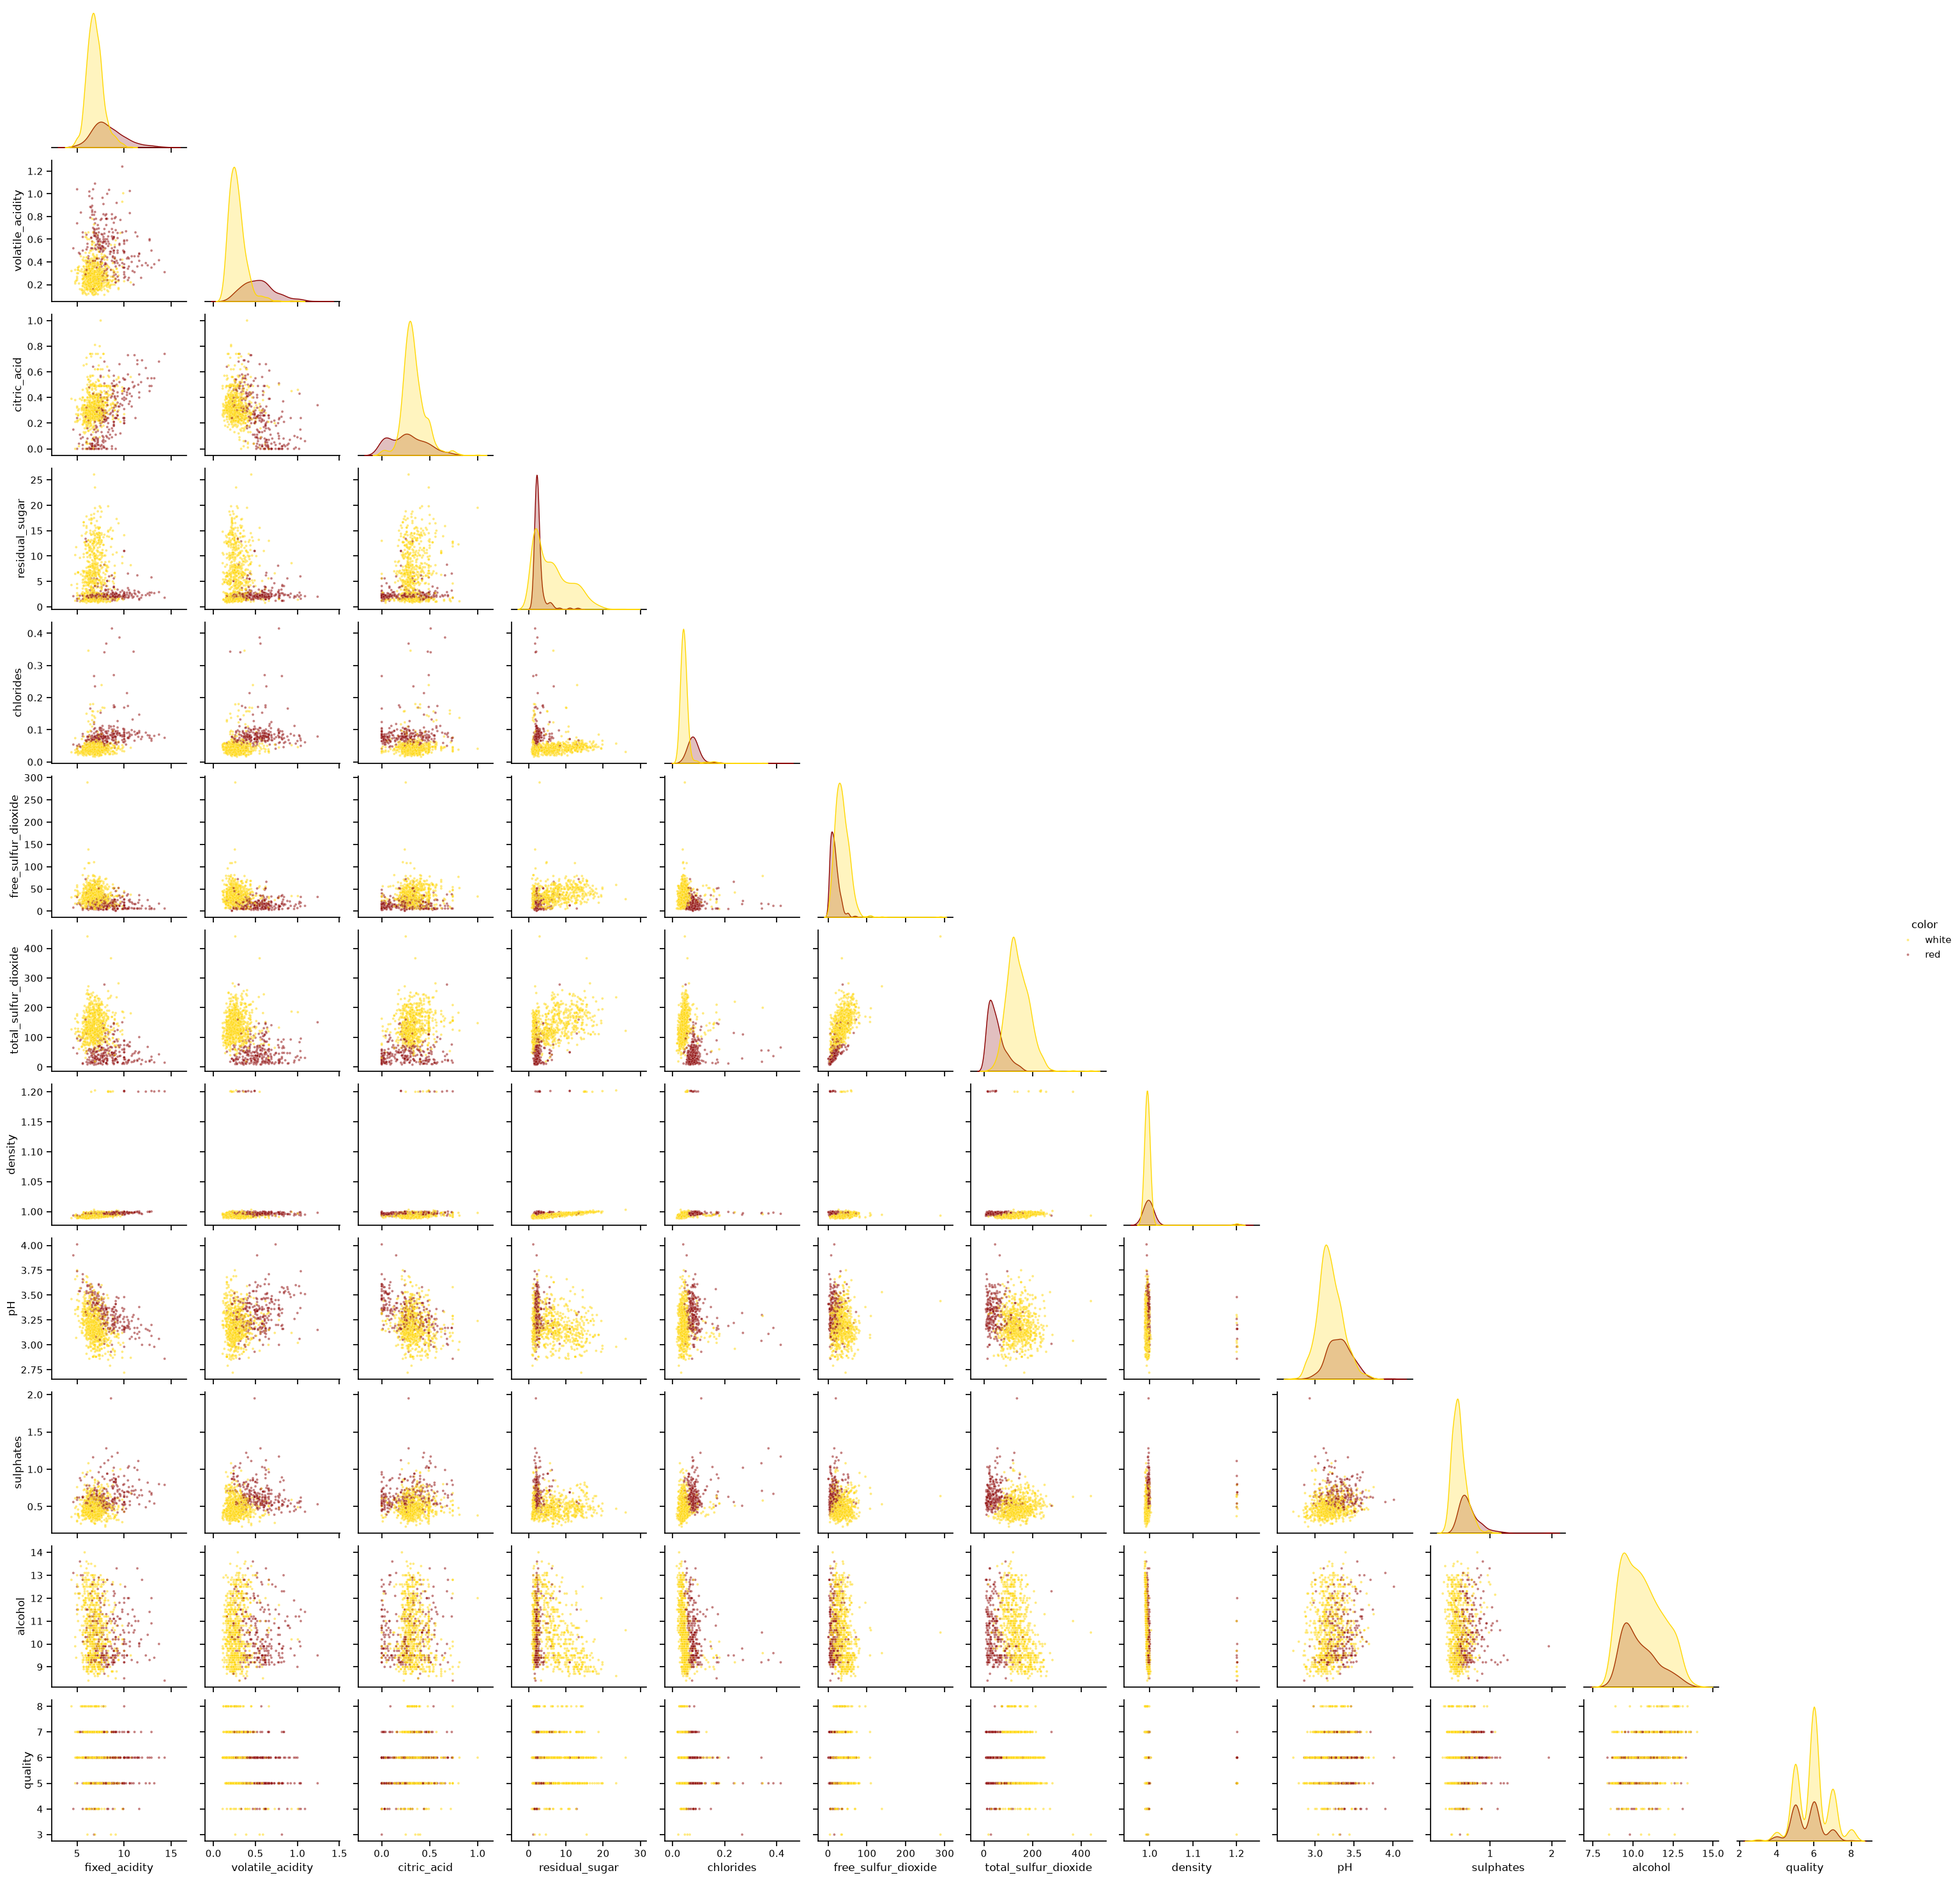

In [5]:
sns.set_context('notebook')
pair_sample = data.sample(1000, random_state=42)
sns.pairplot(pair_sample, hue='color',
             palette={'red': 'darkred', 'white': 'gold'},
             plot_kws={'s': 8, 'alpha': 0.5}, diag_kind='kde', corner=True);

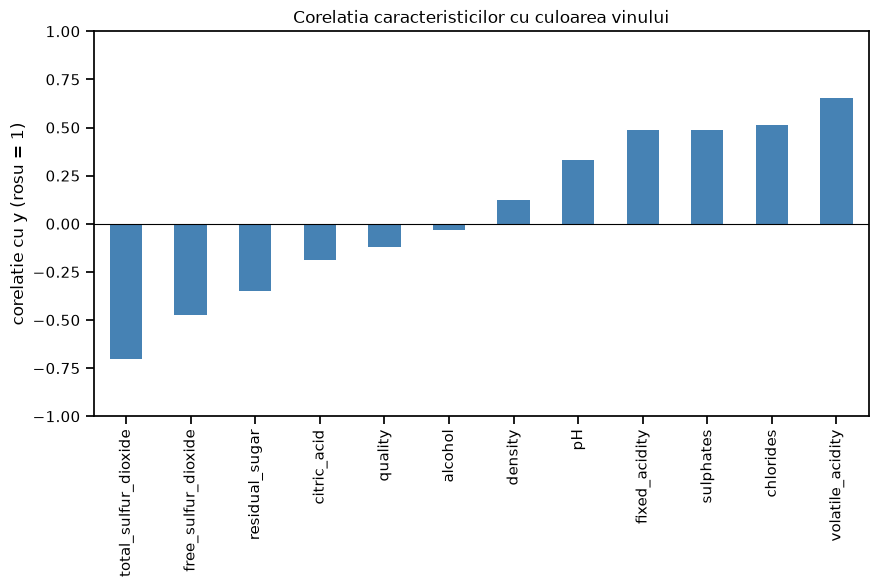

In [6]:
# Corelatia fiecarei coloane cu y
correlations = data[fields].corrwith(y)
correlations = correlations.sort_values()

ax = correlations.plot(kind='bar', figsize=(10, 5), color='steelblue')
ax.set(ylim=[-1, 1], ylabel='corelatie cu y (rosu = 1)', title='Corelatia caracteristicilor cu culoarea vinului')
ax.axhline(0, color='black', linewidth=0.8);

In [7]:
# Selectam cele doua campuri cu cea mai mare corelatie absoluta
fields = correlations.map(abs).sort_values().iloc[-2:].index
print(fields)
X = data[fields]

Index(['volatile_acidity', 'total_sulfur_dioxide'], dtype='str')


In [8]:
# Scalam X in intervalul [0, 1] si il transformam inapoi in DataFrame
scaler = MinMaxScaler()
X = scaler.fit_transform(X)
X = pd.DataFrame(X, columns=['%s_scaled' % fld for fld in fields])
print(X.columns)
X.describe().T[['min', 'max', 'mean']]

Index(['volatile_acidity_scaled', 'total_sulfur_dioxide_scaled'], dtype='str')


,min,max,mean
volatile_acidity_scaled,0.0,1.0,0.173111
total_sulfur_dioxide_scaled,0.0,1.0,0.252868


**Concluzie:** cele doua caracteristici cele mai corelate (in valoare absoluta) cu culoarea sunt `total_sulfur_dioxide` (corelatie negativa - vinurile albe au mult mai mult dioxid de sulf) si `volatile_acidity` (corelatie pozitiva - vinurile rosii au aciditate volatila mai mare). Dupa scalare ambele coloane au valori intre 0 si 1.

## Întrebarea 2

Scopul acestei întrebări este de a analiza pragul de decizie al clasificatorului LinearSVC pentru setul de date dat. Consultați [acest exemplu](http://scikit-learn.org/stable/auto_examples/svm/plot_iris.html#sphx-glr-auto-examples-svm-plot-iris-py) din documentația sklearn.

* Configurați clasificatorul LinearSVC pe `X` și `y`.
* Selectați 300 de eșantioane din `X`. Obțineți valorile corespunzătoare ale `y`. Salvați-le în variabilele `X_color` și `y_color`. Acest lucru se datorează faptului că setul de date original este prea mare și generează un grafic supraîncărcat.
* Modificați `y_color` astfel încât valoarea „roșu” să înlocuiască 1, iar „galben” să înlocuiască 0.
* Graficul de dispersie pentru coloanele X_color. Utilizați argumentul cu cuvântul-cheie „color=y_color” pentru a afișa codul culorii.
* Utilizați fragmentul de cod de mai jos pentru a desena suprafața soluției în culori.


python

x_axis, y_axis = np.arange(0, 1, .005), np.arange(0, 1, .005)

xx, yy = np.meshgrid(x_axis, y_axis)

xx_ravel = xx.ravel()

yy_ravel = yy.ravel()

X_grid = pd.DataFrame([xx_ravel, yy_ravel]). T

y_grid_predictions = *[MODELUL DVS.]*. predict(X_grid)

y_grid_predictions = y_grid_predictions.reshape(xx.shape)

ax.contourf(xx, yy, y_grid_predictions, cmap=plt.cm.autumn_r, alpha=.3)


Nu ezitați să experimentați cu diferite variante de parametri pentru LinearSVC și să examinați marginile de decizie.

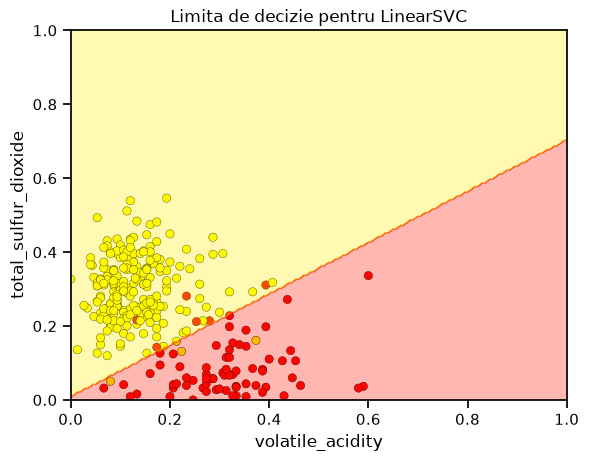

In [9]:
# Antrenam LinearSVC pe X si y
LSVC = LinearSVC()
LSVC.fit(X, y)

# Esantion de 300 de puncte pentru grafic
X_color = X.sample(300, random_state=45)
y_color = y.loc[X_color.index]
y_color = y_color.map(lambda r: 'red' if r == 1 else 'yellow')

ax = plt.axes()
ax.scatter(X_color.iloc[:, 0], X_color.iloc[:, 1], color=y_color, alpha=1, edgecolor='k', linewidth=0.3)

# Suprafata de decizie
x_axis, y_axis = np.arange(0, 1.005, .005), np.arange(0, 1.005, .005)
xx, yy = np.meshgrid(x_axis, y_axis)
xx_ravel = xx.ravel()
yy_ravel = yy.ravel()
X_grid = pd.DataFrame([xx_ravel, yy_ravel]).T
X_grid.columns = X.columns  # aceleasi nume de coloane ca la antrenare
y_grid_predictions = LSVC.predict(X_grid)
y_grid_predictions = y_grid_predictions.reshape(xx.shape)
ax.contourf(xx, yy, y_grid_predictions, cmap=plt.cm.autumn_r, alpha=.3)

ax.set(xlabel=fields[0], ylabel=fields[1], xlim=[0, 1], ylim=[0, 1],
       title='Limita de decizie pentru LinearSVC');

Experimentam cu diferite valori ale parametrului `C` pentru LinearSVC. Un `C` mic inseamna regularizare puternica (margine mai larga), un `C` mare inseamna regularizare slaba.

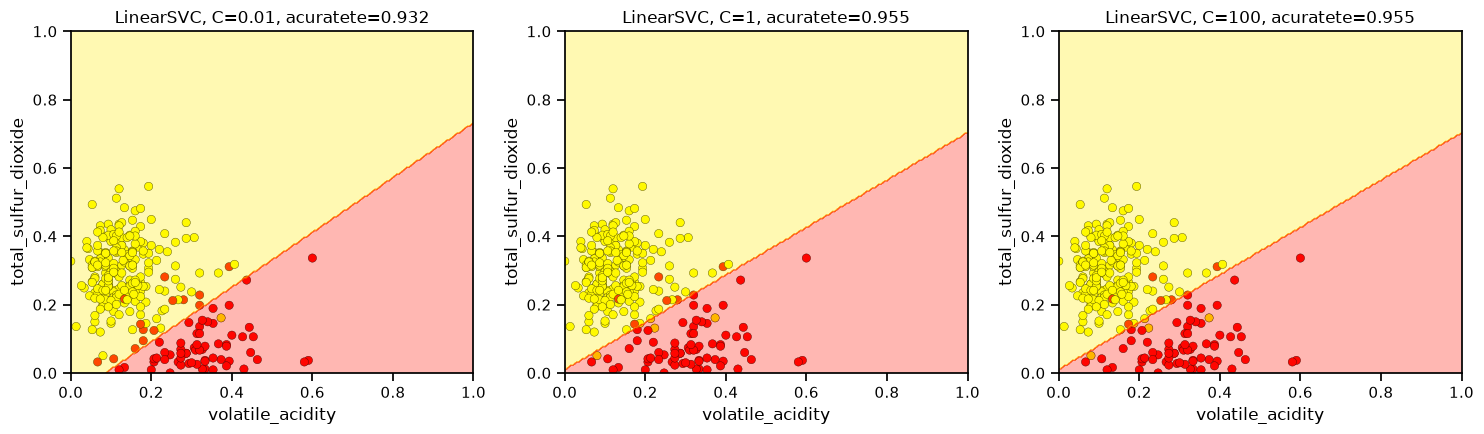

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, C in zip(axes, [0.01, 1, 100]):
    model = LinearSVC(C=C).fit(X, y)
    ax.scatter(X_color.iloc[:, 0], X_color.iloc[:, 1], color=y_color, edgecolor='k', linewidth=0.3)
    pred = model.predict(X_grid).reshape(xx.shape)
    ax.contourf(xx, yy, pred, cmap=plt.cm.autumn_r, alpha=.3)
    ax.set(xlabel=fields[0], ylabel=fields[1], xlim=[0, 1], ylim=[0, 1],
           title='LinearSVC, C=%s, acuratete=%.3f' % (C, model.score(X, y)))
plt.tight_layout();

**Concluzie:** limita de decizie a LinearSVC este o dreapta. Vinurile rosii (rosu) sunt concentrate in zona cu `total_sulfur_dioxide` scazut si `volatile_acidity` ridicata. Pentru valori foarte mici ale lui `C`, regularizarea puternica deplaseaza dreapta si acuratetea scade; pentru `C >= 1` dreapta se stabilizeaza.

## Întrebarea 3

Să extindem acum nucleul Gauss al SVC și să vedem cum se modifică limita de decizie.

* Combinați fragmentele de cod din întrebarea 2 într-o singură funcție, care utilizează estimatorul `X` și `y` și va genera graficul final cu limita de decizie. Pași:
    <ol>
     <li> modelul potrivit
     <li> obțineți un eșantion de 300 de înregistrări din X și valorile corespunzătoare ale lui y
     <li> creați o rețea, faceți predicții, generați un grafic folosind ax.contourf
     <li> adăugați-l la graficul dispersat
    </ol>
* După copierea și inserarea codului, asigurați-vă că funcția finală utilizează `estimatorul` dvs. de intrare, nu modelul LinearSVC creat de dvs.
* Pentru următoarele valori ale lui `gamma`, creați un SVC cu kernel gaussian și desenați curba de decizie.
`gammas = [.5, 1, 2, 10]`
* Menținând `gamma` constantă, pentru diferite valori ale lui `C`, desenați curba de decizie. Puteți încerca
`Cs = [.1, 1, 10]>

In [11]:
def plot_decision_boundary(estimator, X, y, ax=None, title=None):
    """Antreneaza estimatorul pe X, y si deseneaza limita de decizie peste un esantion de 300 de puncte."""
    # 1. antrenam modelul
    estimator.fit(X, y)

    # 2. esantion de 300 de inregistrari si valorile y corespunzatoare
    X_color = X.sample(300, random_state=45)
    y_color = y.loc[X_color.index]
    y_color = y_color.map(lambda r: 'red' if r == 1 else 'yellow')

    # 3. retea de puncte, predictii, contourf
    x_axis, y_axis = np.arange(0, 1.005, .005), np.arange(0, 1.005, .005)
    xx, yy = np.meshgrid(x_axis, y_axis)
    X_grid = pd.DataFrame([xx.ravel(), yy.ravel()]).T
    X_grid.columns = X.columns
    y_grid_predictions = estimator.predict(X_grid).reshape(xx.shape)

    if ax is None:
        ax = plt.axes()
    ax.contourf(xx, yy, y_grid_predictions, cmap=plt.cm.autumn_r, alpha=.3)

    # 4. adaugam graficul de dispersie
    ax.scatter(X_color.iloc[:, 0], X_color.iloc[:, 1], color=y_color, alpha=1, edgecolor='k', linewidth=0.3)
    ax.set(xlabel=X.columns[0], ylabel=X.columns[1], xlim=[0, 1], ylim=[0, 1])
    if title:
        ax.set_title(title)
    return ax

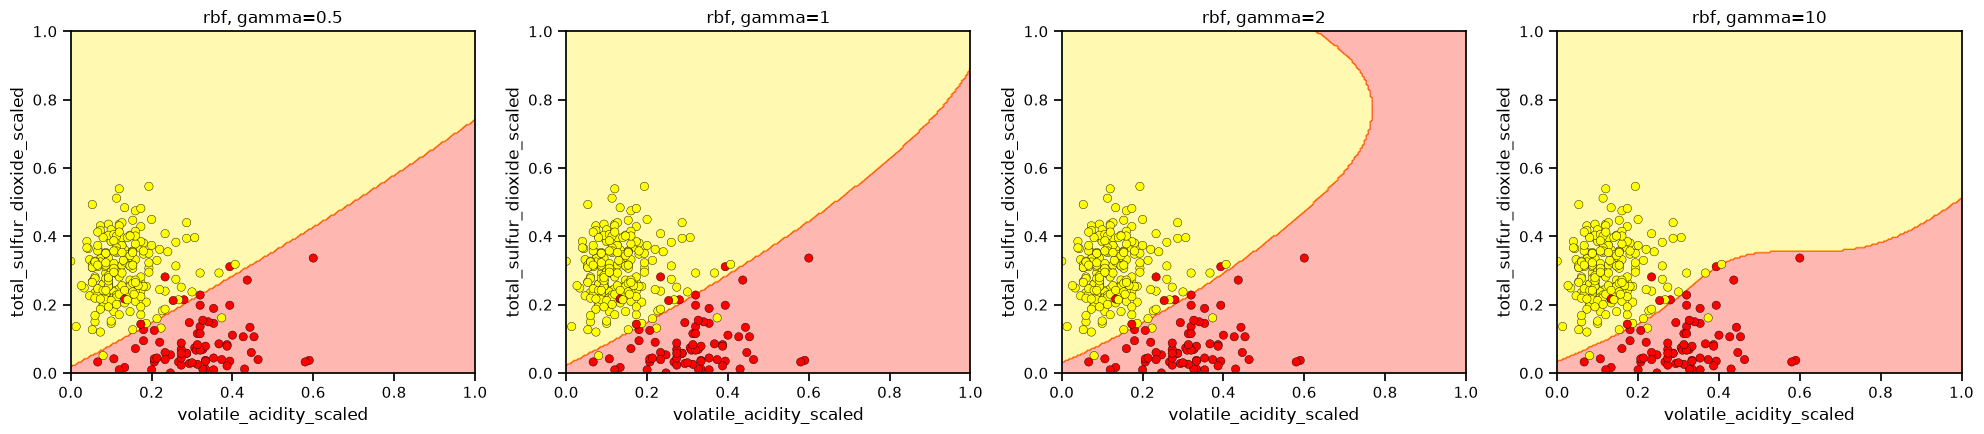

In [12]:
# SVC cu nucleu gaussian (rbf) pentru diferite valori ale lui gamma
gammas = [.5, 1, 2, 10]
fig, axes = plt.subplots(1, len(gammas), figsize=(20, 4.5))
for ax, gamma in zip(axes, gammas):
    SVC_Gaussian = SVC(kernel='rbf', gamma=gamma)
    plot_decision_boundary(SVC_Gaussian, X, y, ax=ax, title='rbf, gamma=%s' % gamma)
plt.tight_layout();

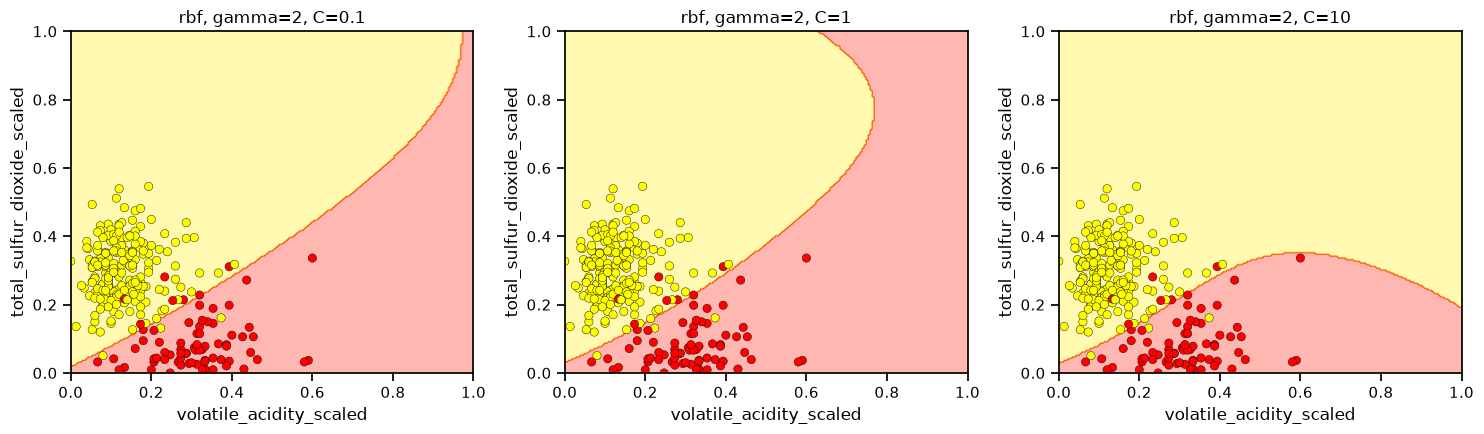

In [13]:
# Gamma constant, variem C
Cs = [.1, 1, 10]
fig, axes = plt.subplots(1, len(Cs), figsize=(15, 4.5))
for ax, C in zip(axes, Cs):
    SVC_Gaussian = SVC(kernel='rbf', gamma=2, C=C)
    plot_decision_boundary(SVC_Gaussian, X, y, ax=ax, title='rbf, gamma=2, C=%s' % C)
plt.tight_layout();

In [14]:
# Acuratetea pe setul de antrenare pentru fiecare combinatie (pentru comparatie)
rows = []
for gamma in gammas:
    for C in Cs:
        m = SVC(kernel='rbf', gamma=gamma, C=C).fit(X, y)
        rows.append({'gamma': gamma, 'C': C, 'acuratete': m.score(X, y)})
pd.DataFrame(rows).pivot(index='gamma', columns='C', values='acuratete').round(4)

C,0.1,1.0,10.0
gamma,,,
0.5,0.9520,0.9554,0.9547
1.0,0.9537,0.9547,0.9551
2.0,0.9540,0.9547,0.9551
10.0,0.9543,0.9551,0.9552


**Concluzie:**
- Spre deosebire de LinearSVC, nucleul gaussian (rbf) produce limite de decizie neliniare (curbe).
- Cu cat `gamma` creste, cu atat influenta fiecarui punct este mai locala, iar limita de decizie devine mai complexa si mai "ondulata" (risc de supraantrenare).
- Parametrul `C` controleaza regularizarea: un `C` mic produce o limita mai neteda (mai multa regularizare), iar un `C` mare incearca sa clasifice corect cat mai multe puncte de antrenare, ceea ce duce la o limita mai complexa.

## Întrebarea 4

În această întrebare vom compara timpul de execuție între SVC și Nystroem cu nucleul rbf.
<br><br>
Jupyter Notebooks oferă o funcție magică utilă, **`%timeit`**, care execută un șir de comandă și afișează timpul necesar pentru execuție. Dacă introduceți **`%timeit`** la începutul unei celule, aceasta va rula întreaga celulă și va afișa timpul de execuție.

* Reîncărcați datele privind calitatea vinului dacă ați adus modificări la original.
* Creați variabila `y` din coloana `data.color` și `X` din celelalte coloane.
* Folosiți `%%timeit` pentru a măsura timpul necesar configurării SVC cu nucleul RBF.
* Folosiți `%%timeit` pentru a măsura timpul necesar următoarei operațiuni: ordonați datele folosind Nystroem, apoi integrați clasificatorul SGD.

Nystroem+SGD va necesita mult mai puțin timp pentru antrenare. Această diferență va fi mai pronunțată dacă setul de date ar fi mai mare.

* Faceți 5 copii ale lui X și corelați-le
* Faceți 5 copii ale lui y și corelați-le
* Comparați timpul necesar pentru antrenarea ambelor metode de mai sus.

In [15]:
# Reincarcam datele originale
data = pd.read_csv(filepath)

# y din coloana color, X din toate celelalte coloane
y = (data['color'] == 'red').astype(int)
X = data.drop('color', axis=1)
print(X.shape)

(6497, 12)


In [16]:
%%timeit -n 1 -r 3
# Timpul de antrenare pentru SVC cu nucleu RBF
kwargs = {'kernel': 'rbf'}
svc = SVC(**kwargs)
svc.fit(X, y)

152 ms ± 25.6 ms per loop (mean ± std. dev. of 3 runs, 1 loop each)


In [17]:
%%timeit -n 1 -r 3
# Timpul de antrenare pentru Nystroem (aproximarea nucleului) + SGDClassifier
kwargs = {'kernel': 'rbf'}
nystroem = Nystroem(**kwargs)
sgd = SGDClassifier()
X_transformed = nystroem.fit_transform(X)
sgd.fit(X_transformed, y)

34.8 ms ± 7.41 ms per loop (mean ± std. dev. of 3 runs, 1 loop each)


Marim setul de date de 5 ori (concatenam 5 copii ale lui X si ale lui y) si comparam din nou timpii de antrenare.

In [18]:
X2 = pd.concat([X] * 5)
y2 = pd.concat([y] * 5)

print(X2.shape)
print(y2.value_counts())

(32485, 12)
color
0    24490
1     7995
Name: count, dtype: int64


In [19]:
%%timeit -n 1 -r 1
svc = SVC(kernel='rbf')
svc.fit(X2, y2)

3.4 s ± 0 ns per loop (mean ± std. dev. of 1 run, 1 loop each)


In [20]:
%%timeit -n 1 -r 3
nystroem = Nystroem(kernel='rbf')
sgd = SGDClassifier()
X2_transformed = nystroem.fit_transform(X2)
sgd.fit(X2_transformed, y2)

137 ms ± 8.5 ms per loop (mean ± std. dev. of 3 runs, 1 loop each)


**Concluzie:** SVC cu nucleu RBF calculeaza (implicit) matricea nucleului intre perechi de observatii, deci timpul de antrenare creste aproximativ patratic (sau mai rau) cu numarul de randuri. Nystroem aproximeaza nucleul folosind doar un numar fix de componente (implicit 100), iar SGDClassifier se antreneaza in timp liniar, astfel ca Nystroem + SGD este mult mai rapid, iar diferenta devine mai pronuntata cand setul de date este de 5 ori mai mare.